In [1]:
# ==============================================================
# LOCAL PROJECT SETUP (added during VS Code migration)
# Portable replacement for Google Colab / Google Drive mounting.
# All research code below this block is unchanged.
# ==============================================================
import sys as _sys
from pathlib import Path as _Path

def _locate_project_root():
    start = _Path.cwd().resolve()
    for candidate in [start] + list(start.parents):
        if (candidate / "src" / "ecg_qpain" / "paths.py").is_file():
            return candidate
    return start

PROJECT_ROOT = _locate_project_root()
_src = str(PROJECT_ROOT / "src")
if _src not in _sys.path:
    _sys.path.insert(0, _src)

from ecg_qpain.paths import (
    ROOT, BASE_DIR, PROJECT_DIR, DRIVE_DIR, MYDRIVE, MOUNT_POINT, mount_path,
    DATA_DIR, RAW_DIR, PROCESSED_DIR, MODELS_DIR, REPORTS_DIR,
    MITDB_DIR, NSTDB_DIR, MITDB_EXTRACTED, NSTDB_EXTRACTED,
    B2_DIR, B3_DIR, B4_DIR,
)
print("Local project root:", PROJECT_ROOT)
# ==============================================================

# (Colab Drive import removed - local execution)
import os

MOUNT_POINT = str(PROJECT_ROOT)

# (Colab mount check removed - local execution; project root is local)

BASE_DIR = str(PROJECT_ROOT)

PROCESSED_DIR = os.path.join(BASE_DIR, "data", "processed")
REPORT_DIR = os.path.join(BASE_DIR, "reports")
MODEL_DIR = os.path.join(BASE_DIR, "models")

MITDB_DIR = os.path.join(
    BASE_DIR,
    "data/raw/mitdb/mit-bih-arrhythmia-database-1.0.0"
)

NSTDB_DIR = os.path.join(
    BASE_DIR,
    "data/raw/nstdb/mit-bih-noise-stress-test-database-1.0.0"
)

os.makedirs(MODEL_DIR, exist_ok=True)

print("Google Drive mounted:", os.path.ismount(MOUNT_POINT))
print("Processed data:", os.path.exists(PROCESSED_DIR))
print("Noise dataset:", os.path.exists(NSTDB_DIR))
print("Reports:", os.path.exists(REPORT_DIR))

Mounted at /content/gdrive_mount
Google Drive mounted: True
Processed data: True
Noise dataset: True
Reports: True


In [2]:
# (pip install moved to requirements.txt; run: pip install -r requirements.txt)

import os
import json
import random
import numpy as np
import pandas as pd
import tensorflow as tf
import wfdb
import matplotlib.pyplot as plt

from sklearn.utils.class_weight import compute_class_weight
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    f1_score
)

SEED = 2027

np.random.seed(SEED)
random.seed(SEED)
tf.random.set_seed(SEED)

print("TensorFlow:", tf.__version__)
print("WFDB imported successfully!")
print("Libraries ready!")

TensorFlow: 2.21.0
WFDB imported successfully!
Libraries ready!


In [3]:
train_data = np.load(
    os.path.join(PROCESSED_DIR, "train_beats.npz")
)

X_train = train_data["X"].astype(np.float32)
y_train = train_data["y"].astype(np.int32)

val_data = np.load(
    os.path.join(PROCESSED_DIR, "validation_beats.npz")
)

X_val = val_data["X"].astype(np.float32)
y_val = val_data["y"].astype(np.int32)

# Add channel dimension
X_train = X_train[..., np.newaxis]
X_val = X_val[..., np.newaxis]

print("Training:", X_train.shape)
print("Validation:", X_val.shape)

print("Training classes:", np.unique(y_train))
print("Validation classes:", np.unique(y_val))

Training: (59720, 288, 1)
Validation: (19530, 288, 1)
Training classes: [0 1 2 3]
Validation classes: [0 1 2 3]


In [4]:
config_path = os.path.join(
    REPORT_DIR,
    "noise_generation_config.json"
)

with open(config_path, "r") as f:
    noise_config = json.load(f)

FS = noise_config["sampling_frequency"]
BEAT_LENGTH = noise_config["beat_length"]

TRAIN_SNRS = noise_config["train_snrs"]
VALIDATION_SNRS = noise_config["validation_snrs"]

NOISE_SPLIT_RANGES = noise_config["split_ranges"]

print("Sampling frequency:", FS)
print("Beat length:", BEAT_LENGTH)

print("Training SNRs:", TRAIN_SNRS)
print("Validation SNRs:", VALIDATION_SNRS)

print("Noise split ranges:", NOISE_SPLIT_RANGES)

Sampling frequency: 360
Beat length: 288
Training SNRs: [24, 18, 12, 6]
Validation SNRs: [18, 12, 6]
Noise split ranges: {'train': [0, 390000], 'validation': [390000, 520000], 'test': [520000, 650000]}


In [5]:
noise_types = ["bw", "ma"]

noise_signals = {}

for noise_type in noise_types:

    noise_path = os.path.join(
        NSTDB_DIR,
        noise_type
    )

    signal, fields = wfdb.rdsamp(noise_path)

    noise_signals[noise_type] = signal[:, 0].astype(
        np.float32
    )

    print(
        noise_type.upper(),
        "Shape:",
        signal.shape,
        "Sampling Frequency:",
        fields["fs"]
    )

BW Shape: (650000, 2) Sampling Frequency: 360
MA Shape: (650000, 2) Sampling Frequency: 360


In [6]:
train_start, train_end = NOISE_SPLIT_RANGES["train"]

val_start, val_end = NOISE_SPLIT_RANGES["validation"]

test_start, test_end = NOISE_SPLIT_RANGES["test"]

assert train_end <= val_start
assert val_end <= test_start

print("Training noise region:", train_start, train_end)
print("Validation noise region:", val_start, val_end)
print("Test noise region:", test_start, test_end)

print("Cross-split noise overlap: NONE")

Training noise region: 0 390000
Validation noise region: 390000 520000
Test noise region: 520000 650000
Cross-split noise overlap: NONE


In [7]:
noise_bank = np.stack([
    noise_signals["bw"],
    noise_signals["ma"]
], axis=0)

noise_bank = tf.constant(
    noise_bank,
    dtype=tf.float32
)

TRAIN_START = int(train_start)
TRAIN_END = int(train_end)

VAL_START = int(val_start)
VAL_END = int(val_end)

print("Noise bank shape:", noise_bank.shape)
print("Noise types:", noise_types)
print("Training noise bank ready!")

Noise bank shape: (2, 650000)
Noise types: ['bw', 'ma']
Training noise bank ready!


In [8]:
def augment_training_beat(ecg, label):

    ecg = tf.cast(ecg, tf.float32)

    # Random noise type: 0=BW, 1=MA
    noise_index = tf.random.uniform(
        shape=[],
        minval=0,
        maxval=2,
        dtype=tf.int32
    )

    # Random noise segment
    start = tf.random.uniform(
        shape=[],
        minval=TRAIN_START,
        maxval=TRAIN_END - BEAT_LENGTH + 1,
        dtype=tf.int32
    )

    indices = tf.range(
        start,
        start + BEAT_LENGTH
    )

    noise = tf.gather(
        noise_bank[noise_index],
        indices
    )

    # Remove DC component
    noise = noise - tf.reduce_mean(noise)

    # Random SNR
    snr_index = tf.random.uniform(
        shape=[],
        minval=0,
        maxval=len(TRAIN_SNRS),
        dtype=tf.int32
    )

    snr_db = tf.gather(
        tf.constant(TRAIN_SNRS, dtype=tf.float32),
        snr_index
    )

    signal_power = tf.reduce_mean(tf.square(ecg))
    noise_power = tf.reduce_mean(tf.square(noise))

    target_noise_power = (
        signal_power /
        tf.pow(10.0, snr_db / 10.0)
    )

    scale = tf.sqrt(
        target_noise_power /
        tf.maximum(noise_power, 1e-12)
    )

    noisy_ecg = ecg + noise * scale

    return noisy_ecg, label


print("Online noise augmentation function ready!")

Online noise augmentation function ready!


In [9]:
BATCH_SIZE = 128
EPOCHS = 30

AUTOTUNE = tf.data.AUTOTUNE

train_dataset = tf.data.Dataset.from_tensor_slices(
    (X_train, y_train)
)

train_dataset = train_dataset.shuffle(
    buffer_size=10000,
    seed=SEED,
    reshuffle_each_iteration=True
)

train_dataset = train_dataset.map(
    augment_training_beat,
    num_parallel_calls=AUTOTUNE
)

train_dataset = train_dataset.batch(
    BATCH_SIZE
).prefetch(AUTOTUNE)

print("Training dataset created!")
print("Batch size:", BATCH_SIZE)
print("Maximum epochs:", EPOCHS)

Training dataset created!
Batch size: 128
Maximum epochs: 30


In [10]:
def create_noisy_validation_data():

    rng = np.random.default_rng(SEED)

    X_noisy = np.empty_like(X_val)

    for i in range(len(X_val)):

        noise_index = rng.integers(0, 2)

        noise_start = rng.integers(
            VAL_START,
            VAL_END - BEAT_LENGTH + 1
        )

        noise = noise_signals[
            noise_types[noise_index]
        ][noise_start:noise_start + BEAT_LENGTH].copy()

        noise = noise.astype(np.float32)
        noise = noise - np.mean(noise)

        snr_db = rng.choice(VALIDATION_SNRS)

        clean = X_val[i, :, 0]

        signal_power = np.mean(clean ** 2)
        noise_power = np.mean(noise ** 2)

        target_noise_power = (
            signal_power / (10 ** (snr_db / 10))
        )

        scale = np.sqrt(
            target_noise_power /
            max(noise_power, 1e-12)
        )

        X_noisy[i, :, 0] = clean + noise * scale

    return X_noisy


X_val_noisy = create_noisy_validation_data()

print("Noisy validation shape:", X_val_noisy.shape)
print("Validation labels shape:", y_val.shape)
print("Noisy validation generated!")

Noisy validation shape: (19530, 288, 1)
Validation labels shape: (19530,)
Noisy validation generated!


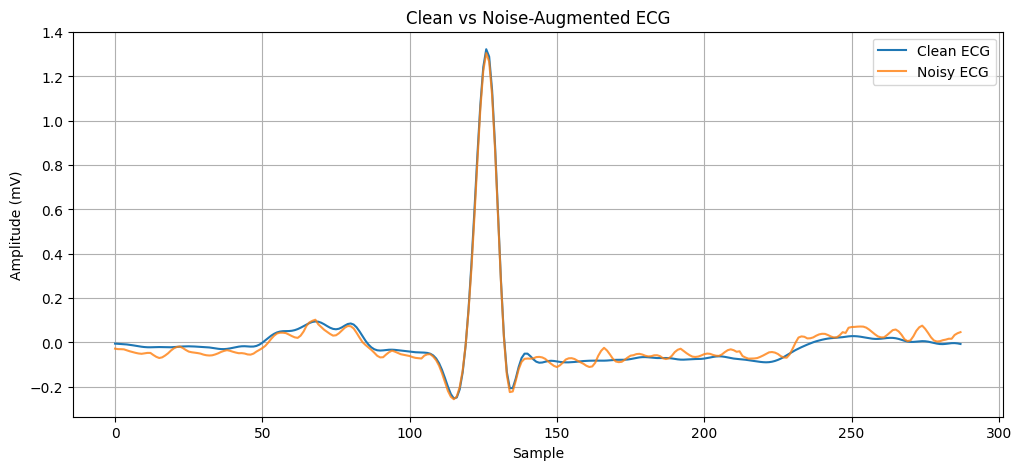

In [11]:
sample_index = 100

plt.figure(figsize=(12, 5))

plt.plot(
    X_val[sample_index, :, 0],
    label="Clean ECG"
)

plt.plot(
    X_val_noisy[sample_index, :, 0],
    label="Noisy ECG",
    alpha=0.8
)

plt.title("Clean vs Noise-Augmented ECG")
plt.xlabel("Sample")
plt.ylabel("Amplitude (mV)")
plt.legend()
plt.grid()

plt.show()

In [12]:
classes = np.unique(y_train)

weights = compute_class_weight(
    class_weight="balanced",
    classes=classes,
    y=y_train
)

class_weights = {
    int(c): float(w)
    for c, w in zip(classes, weights)
}

print("Class weights:")

for c, w in class_weights.items():
    print(f"Class {c}: {w:.4f}")

Class weights:
Class 0: 0.2811
Class 1: 7.6329
Class 2: 3.5337
Class 3: 35.5476


In [13]:
def residual_block(x, filters, kernel_size=5, stride=1):

    shortcut = x

    x = tf.keras.layers.Conv1D(
        filters,
        kernel_size,
        strides=stride,
        padding="same",
        use_bias=False
    )(x)

    x = tf.keras.layers.BatchNormalization()(x)
    x = tf.keras.layers.Activation("relu")(x)

    x = tf.keras.layers.Conv1D(
        filters,
        kernel_size,
        padding="same",
        use_bias=False
    )(x)

    x = tf.keras.layers.BatchNormalization()(x)

    if shortcut.shape[-1] != filters or stride != 1:

        shortcut = tf.keras.layers.Conv1D(
            filters,
            kernel_size=1,
            strides=stride,
            padding="same",
            use_bias=False
        )(shortcut)

        shortcut = tf.keras.layers.BatchNormalization()(shortcut)

    x = tf.keras.layers.Add()([x, shortcut])

    x = tf.keras.layers.Activation("relu")(x)

    return x


def build_resnet_model():

    inputs = tf.keras.layers.Input(
        shape=(288, 1)
    )

    x = tf.keras.layers.Conv1D(
        32,
        kernel_size=7,
        padding="same",
        use_bias=False
    )(inputs)

    x = tf.keras.layers.BatchNormalization()(x)
    x = tf.keras.layers.Activation("relu")(x)

    x = residual_block(x, 32)
    x = residual_block(x, 64, stride=2)
    x = residual_block(x, 128, stride=2)

    x = tf.keras.layers.GlobalAveragePooling1D()(x)

    x = tf.keras.layers.Dense(
        128,
        activation="relu"
    )(x)

    x = tf.keras.layers.Dropout(0.4)(x)

    outputs = tf.keras.layers.Dense(
        4,
        activation="softmax"
    )(x)

    return tf.keras.Model(inputs, outputs)


resnet_model = build_resnet_model()

resnet_model.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=0.001
    ),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

resnet_model.summary()

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer         │ (None, 288, 1)    │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d (Conv1D)     │ (None, 288, 32)   │        224 │ input_layer[0][0] │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalization │ (None, 288, 32)   │        128 │ conv1d[0][0]      │
│ (BatchNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation          │ (None, 288, 32)   │          0 │ batch_normalizat… │
│ (Activation)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_1 (Conv1D)   │ (None, 288, 32)   │      5,120 │ activation[0][0]  │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 288, 32)   │        128 │ conv1d_1[0][0]    │
│ (BatchNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_1        │ (None, 288, 32)   │          0 │ batch_normalizat… │
│ (Activation)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_2 (Conv1D)   │ (None, 288, 32)   │      5,120 │ activation_1[0][… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 288, 32)   │        128 │ conv1d_2[0][0]    │
│ (BatchNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add (Add)           │ (None, 288, 32)   │          0 │ batch_normalizat… │
│                     │                   │            │ activation[0][0]  │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_2        │ (None, 288, 32)   │          0 │ add[0][0]         │
│ (Activation)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_3 (Conv1D)   │ (None, 144, 64)   │     10,240 │ activation_2[0][… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 144, 64)   │        256 │ conv1d_3[0][0]    │
│ (BatchNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_3        │ (None, 144, 64)   │          0 │ batch_normalizat… │
│ (Activation)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_4 (Conv1D)   │ (None, 144, 64)   │     20,480 │ activation_3[0][… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_5 (Conv1D)   │ (None, 144, 64)   │      2,048 │ activation_2[0][… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 144, 64)   │        256 │ conv1d_4[0][0]    │
│ (BatchNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 144, 64)   │        256 │ conv1d_5[0][0]    │
│ (BatchNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add_1 (Add)         │ (None, 144, 64)   │          0 │ batch_normalizat

 Total params: 194,020 (757.89 KB)

 Trainable params: 192,676 (752.64 KB)

 Non-trainable params: 1,344 (5.25 KB)

In [14]:
B2_DIR = os.path.join(
    MODEL_DIR,
    "B2_Noise_Augmented_ResNet"
)

os.makedirs(B2_DIR, exist_ok=True)

checkpoint_path = os.path.join(
    B2_DIR,
    "best_B2_resnet.keras"
)

checkpoint_callback = tf.keras.callbacks.ModelCheckpoint(
    filepath=checkpoint_path,
    monitor="val_loss",
    save_best_only=True,
    save_weights_only=False,
    verbose=1
)

early_stopping = tf.keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=5,
    restore_best_weights=True,
    verbose=1
)

reduce_lr = tf.keras.callbacks.ReduceLROnPlateau(
    monitor="val_loss",
    factor=0.5,
    patience=3,
    min_lr=1e-6,
    verbose=1
)

print("Checkpoint ready!")
print("Path:", checkpoint_path)

Checkpoint ready!
Path: /content/gdrive_mount/MyDrive/ECG_QPAIN_2027/models/B2_Noise_Augmented_ResNet/best_B2_resnet.keras


In [15]:
b2_history = resnet_model.fit(
    train_dataset,
    validation_data=(X_val_noisy, y_val),
    epochs=EPOCHS,
    class_weight=class_weights,
    callbacks=[
        checkpoint_callback,
        early_stopping,
        reduce_lr
    ],
    verbose=1
)

Epoch 1/30


InvalidArgumentError: Graph execution error:

Detected at node convolution_0 defined at (most recent call last):
<stack traces unavailable>
Depth of output must be a multiple of the number of groups: 32 vs 288

Stack trace for op definition: 
dummy_file_name:10:dummy_function_name

	 [[{{node convolution_0}}]]
	tf2xla conversion failed while converting __forward__conv_xla_5636[]. Run with TF_DUMP_GRAPH_PREFIX=/path/to/dump/dir and --vmodule=xla_compiler=2 to obtain a dump of the compiled functions.
	 [[StatefulPartitionedCall/functional_1/conv1d_1/StatefulPartitionedCall]] [Op:__inference_multi_step_on_iterator_7113]

In [16]:
def augment_training_beat(ecg, label):

    ecg = tf.cast(ecg, tf.float32)

    # Convert (288, 1) to (288,)
    ecg = tf.squeeze(ecg, axis=-1)

    # Random noise type: 0=BW, 1=MA
    noise_index = tf.random.uniform(
        shape=[],
        minval=0,
        maxval=2,
        dtype=tf.int32
    )

    # Random noise segment
    start = tf.random.uniform(
        shape=[],
        minval=TRAIN_START,
        maxval=TRAIN_END - BEAT_LENGTH + 1,
        dtype=tf.int32
    )

    indices = tf.range(
        start,
        start + BEAT_LENGTH
    )

    noise = tf.gather(
        noise_bank[noise_index],
        indices
    )

    noise = noise - tf.reduce_mean(noise)

    # Random SNR
    snr_index = tf.random.uniform(
        shape=[],
        minval=0,
        maxval=len(TRAIN_SNRS),
        dtype=tf.int32
    )

    snr_db = tf.gather(
        tf.constant(TRAIN_SNRS, dtype=tf.float32),
        snr_index
    )

    signal_power = tf.reduce_mean(tf.square(ecg))
    noise_power = tf.reduce_mean(tf.square(noise))

    target_noise_power = (
        signal_power /
        tf.pow(10.0, snr_db / 10.0)
    )

    scale = tf.sqrt(
        target_noise_power /
        tf.maximum(noise_power, 1e-12)
    )

    noisy_ecg = ecg + noise * scale

    # Convert back to (288, 1)
    noisy_ecg = tf.expand_dims(noisy_ecg, axis=-1)

    return noisy_ecg, label


print("Corrected augmentation function ready!")

Corrected augmentation function ready!


In [17]:
train_dataset = tf.data.Dataset.from_tensor_slices(
    (X_train, y_train)
)

train_dataset = train_dataset.shuffle(
    buffer_size=10000,
    seed=SEED,
    reshuffle_each_iteration=True
)

train_dataset = train_dataset.map(
    augment_training_beat,
    num_parallel_calls=tf.data.AUTOTUNE
)

train_dataset = train_dataset.batch(
    BATCH_SIZE
).prefetch(tf.data.AUTOTUNE)

print("Training dataset recreated!")

Training dataset recreated!


In [18]:
for sample_x, sample_y in train_dataset.take(1):

    print("Batch ECG shape:", sample_x.shape)
    print("Batch labels shape:", sample_y.shape)

    print("NaN values:", tf.reduce_sum(
        tf.cast(tf.math.is_nan(sample_x), tf.int32)
    ).numpy())

    print("Infinite values:", tf.reduce_sum(
        tf.cast(tf.math.is_inf(sample_x), tf.int32)
    ).numpy())

    assert sample_x.shape[1:] == (288, 1)
    assert sample_y.shape[0] == sample_x.shape[0]

print("SHAPE VALIDATION PASSED!")

Batch ECG shape: (128, 288, 1)
Batch labels shape: (128,)
NaN values: 0
Infinite values: 0
SHAPE VALIDATION PASSED!


In [19]:
b2_history = resnet_model.fit(
    train_dataset,
    validation_data=(X_val_noisy, y_val),
    epochs=EPOCHS,
    class_weight=class_weights,
    callbacks=[
        checkpoint_callback,
        early_stopping,
        reduce_lr
    ],
    verbose=1
)

Epoch 1/30
467/467 ━━━━━━━━━━━━━━━━━━━━ 0s 496ms/step - accuracy: 0.8314 - loss: 0.4331
Epoch 1: val_loss improved from None to 1.68343, saving model to /content/gdrive_mount/MyDrive/ECG_QPAIN_2027/models/B2_Noise_Augmented_ResNet/best_B2_resnet.keras

Epoch 1: finished saving model to /content/gdrive_mount/MyDrive/ECG_QPAIN_2027/models/B2_Noise_Augmented_ResNet/best_B2_resnet.keras
467/467 ━━━━━━━━━━━━━━━━━━━━ 254s 539ms/step - accuracy: 0.7635 - loss: 0.6109 - val_accuracy: 0.3636 - val_loss: 1.6834 - learning_rate: 0.0010
Epoch 2/30
467/467 ━━━━━━━━━━━━━━━━━━━━ 0s 505ms/step - accuracy: 0.8548 - loss: 0.4175
Epoch 2: val_loss improved from 1.68343 to 1.01538, saving model to /content/gdrive_mount/MyDrive/ECG_QPAIN_2027/models/B2_Noise_Augmented_ResNet/best_B2_resnet.keras

Epoch 2: finished saving model to /content/gdrive_mount/MyDrive/ECG_QPAIN_2027/models/B2_Noise_Augmented_ResNet/best_B2_resnet.keras
467/467 ━━━━━━━━━━━━━━━━━━━━ 265s 550ms/step - accuracy: 0.8167 - loss: 0.5359 -

In [20]:
# Step 16: Evaluate Best B2 Model

val_loss, val_accuracy = resnet_model.evaluate(
    X_val_noisy,
    y_val,
    verbose=1
)

print("B2 Best Validation Loss:", val_loss)
print("B2 Best Validation Accuracy:", val_accuracy)

611/611 ━━━━━━━━━━━━━━━━━━━━ 22s 35ms/step - accuracy: 0.6093 - loss: 0.9275
B2 Best Validation Loss: 0.9274755716323853
B2 Best Validation Accuracy: 0.6092677712440491


In [21]:
# Step 17: Classification Report

y_val_pred_prob = resnet_model.predict(
    X_val_noisy,
    verbose=1
)

y_val_pred = np.argmax(y_val_pred_prob, axis=1)

print(classification_report(
    y_val,
    y_val_pred,
    target_names=["N", "S", "V", "F"],
    zero_division=0
))

611/611 ━━━━━━━━━━━━━━━━━━━━ 21s 34ms/step
              precision    recall  f1-score   support

           N       0.94      0.63      0.75     17533
           S       0.01      0.19      0.03       462
           V       0.80      0.50      0.62      1518
           F       0.00      0.00      0.00        17

    accuracy                           0.61     19530
   macro avg       0.44      0.33      0.35     19530
weighted avg       0.90      0.61      0.73     19530



In [22]:
# Step 18: Save Validation Results

from sklearn.metrics import accuracy_score, f1_score

b2_results = {
    "Model": "B2_ResNet_Noise_Augmented",
    "Best_Epoch": 3,
    "Validation_Loss": float(val_loss),
    "Validation_Accuracy": float(accuracy_score(y_val, y_val_pred)),
    "Macro_F1": float(f1_score(y_val, y_val_pred, average="macro")),
    "Weighted_F1": float(f1_score(y_val, y_val_pred, average="weighted"))
}

b2_results_df = pd.DataFrame([b2_results])

results_path = os.path.join(
    REPORT_DIR,
    "B2_noise_augmented_validation_results.csv"
)

b2_results_df.to_csv(results_path, index=False)

print(b2_results_df)
print("\nSaved:", results_path)

                       Model  Best_Epoch  Validation_Loss  \
0  B2_ResNet_Noise_Augmented           3         0.927476   

   Validation_Accuracy  Macro_F1  Weighted_F1  
0             0.609268   0.34968     0.725135  

Saved: /content/gdrive_mount/MyDrive/ECG_QPAIN_2027/reports/B2_noise_augmented_validation_results.csv


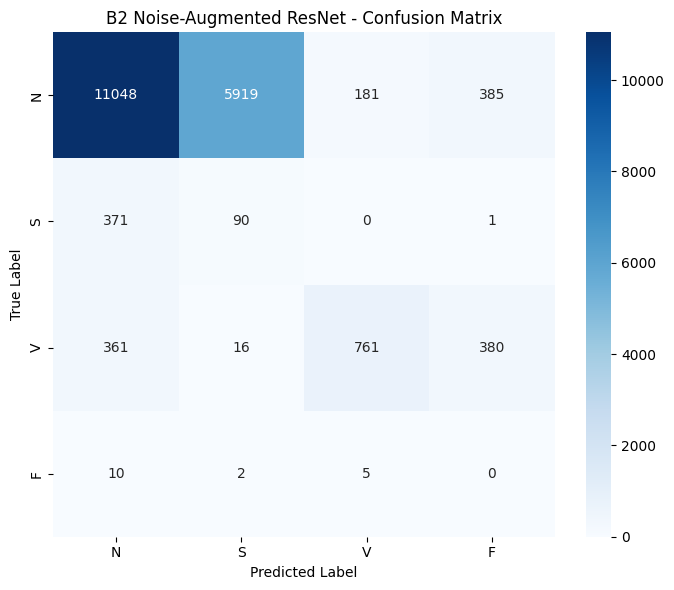

Confusion Matrix:
[[11048  5919   181   385]
 [  371    90     0     1]
 [  361    16   761   380]
 [   10     2     5     0]]


In [23]:
# Step 19: Confusion Matrix

import seaborn as sns

cm = confusion_matrix(y_val, y_val_pred)

plt.figure(figsize=(7, 6))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["N", "S", "V", "F"],
    yticklabels=["N", "S", "V", "F"]
)

plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.title("B2 Noise-Augmented ResNet - Confusion Matrix")
plt.tight_layout()
plt.show()

print("Confusion Matrix:")
print(cm)

In [24]:
# Step 20: Save Confusion Matrix

cm_path = os.path.join(
    REPORT_DIR,
    "B2_noise_augmented_confusion_matrix.csv"
)

cm_df = pd.DataFrame(
    cm,
    index=["True_N", "True_S", "True_V", "True_F"],
    columns=["Pred_N", "Pred_S", "Pred_V", "Pred_F"]
)

cm_df.to_csv(cm_path)

print(cm_df)
print("\nSaved:", cm_path)

        Pred_N  Pred_S  Pred_V  Pred_F
True_N   11048    5919     181     385
True_S     371      90       0       1
True_V     361      16     761     380
True_F      10       2       5       0

Saved: /content/gdrive_mount/MyDrive/ECG_QPAIN_2027/reports/B2_noise_augmented_confusion_matrix.csv


In [25]:
# Step 21: Save Training History

history_df = pd.DataFrame(b2_history.history)

history_path = os.path.join(
    REPORT_DIR,
    "B2_training_history.csv"
)

history_df.to_csv(history_path, index=False)

print(history_df)
print("\nSaved:", history_path)

   accuracy      loss  val_accuracy  val_loss  learning_rate
0  0.763530  0.610944      0.363594  1.683427         0.0010
1  0.816711  0.535859      0.596979  1.015380         0.0010
2  0.840824  0.507014      0.609268  0.927476         0.0010
3  0.871283  0.475887      0.499642  1.501761         0.0010
4  0.887090  0.430888      0.545673  1.209000         0.0010
5  0.896484  0.404553      0.522069  1.286627         0.0010
6  0.909226  0.370049      0.460625  1.497495         0.0005
7  0.915874  0.354778      0.579672  1.048221         0.0005

Saved: /content/gdrive_mount/MyDrive/ECG_QPAIN_2027/reports/B2_training_history.csv


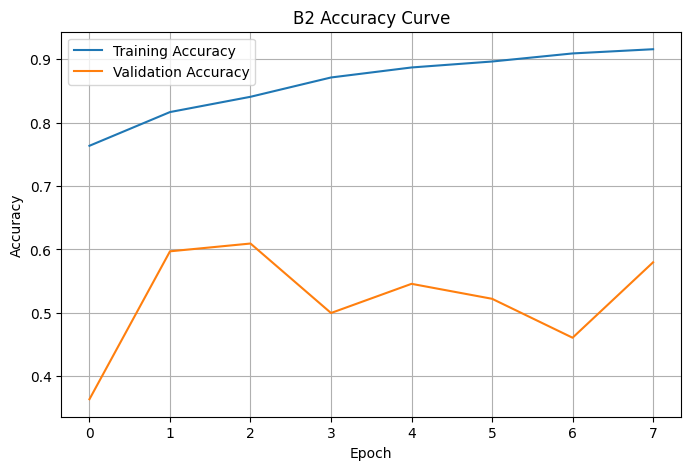

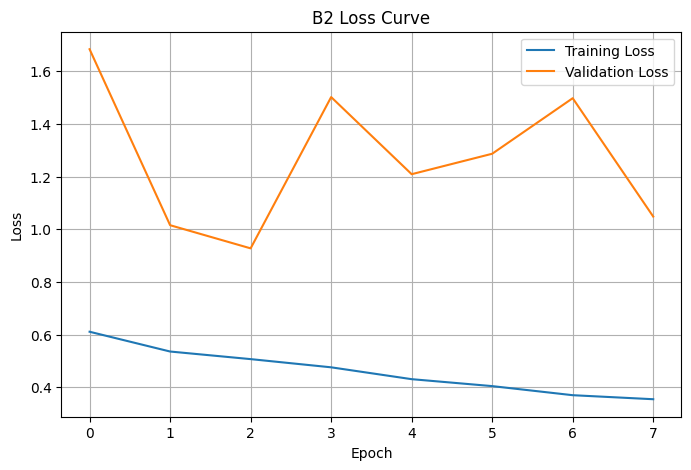

In [26]:
# Step 22: Plot Training Curves

plt.figure(figsize=(8, 5))

plt.plot(
    b2_history.history["accuracy"],
    label="Training Accuracy"
)

plt.plot(
    b2_history.history["val_accuracy"],
    label="Validation Accuracy"
)

plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("B2 Accuracy Curve")
plt.legend()
plt.grid(True)
plt.show()


plt.figure(figsize=(8, 5))

plt.plot(
    b2_history.history["loss"],
    label="Training Loss"
)

plt.plot(
    b2_history.history["val_loss"],
    label="Validation Loss"
)

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("B2 Loss Curve")
plt.legend()
plt.grid(True)
plt.show()

In [27]:
# Step 23: Reload Best B2 Model

best_model_path = os.path.join(
    MODEL_DIR,
    "B2_Noise_Augmented_ResNet",
    "best_B2_resnet.keras"
)

assert os.path.exists(best_model_path), "B2 model not found!"

loaded_b2_model = tf.keras.models.load_model(best_model_path)

print("Best B2 model loaded successfully!")
print("Model input shape:", loaded_b2_model.input_shape)
print("Model output shape:", loaded_b2_model.output_shape)

Best B2 model loaded successfully!
Model input shape: (None, 288, 1)
Model output shape: (None, 4)


In [28]:
# Step 24: Final B2 Validation

required_files = [
    best_model_path,
    os.path.join(REPORT_DIR, "B2_noise_augmented_validation_results.csv"),
    cm_path,
    history_path
]

for file_path in required_files:
    print(
        os.path.basename(file_path),
        ":",
        "OK" if os.path.exists(file_path) else "MISSING"
    )

assert all(os.path.exists(p) for p in required_files)

print("\nB2 MODEL:", "OK")
print("B2 VALIDATION RESULTS:", "OK")
print("CONFUSION MATRIX:", "OK")
print("TRAINING HISTORY:", "OK")
print("TEST DATASET:", "UNTOUCHED")

print("\nNOTEBOOK 06 COMPLETED SUCCESSFULLY!")

best_B2_resnet.keras : OK
B2_noise_augmented_validation_results.csv : OK
B2_noise_augmented_confusion_matrix.csv : OK
B2_training_history.csv : OK

B2 MODEL: OK
B2 VALIDATION RESULTS: OK
CONFUSION MATRIX: OK
TRAINING HISTORY: OK
TEST DATASET: UNTOUCHED

NOTEBOOK 06 COMPLETED SUCCESSFULLY!
